# Moanna-style multi-task autoencoder (Keras)

Re-implementation of the semi-supervised autoencoder + multi-task classifier from Lupat et al., *IEEE Access* 2023. Outputs: ERStatus, HER2Status, Pam50Subtype, Pam50SubtypeSingleLuminal, BasalNonBasal, Luminal, plus input reconstruction.

In [2]:
import tarfile
from pathlib import Path
import pandas as pd

def find_data_dir(name="data", start=None):
    """Search the current folder and its parents for a folder called `name`."""
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        candidate = folder / name
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError(f"No '{name}' folder found above {start}")

DATA_DIR = find_data_dir()
print("DATA_DIR:", DATA_DIR)

# Find the archive (.gz, .tar.gz or .tgz) without hardcoding the exact name
src = next(DATA_DIR.glob("moanna_training_data*"), None)
if src is None:
    raise FileNotFoundError(f"No moanna_training_data* file in {DATA_DIR}")
print("Archive:", src)

out_dir = DATA_DIR / "extracted"
if not out_dir.exists():                      
    with tarfile.open(src, "r:*") as tar:     
        tar.extractall(out_dir)

# Locate the extracted files wherever they ended up
dat_path = next(out_dir.rglob("moanna_training_data.tsv"))
lab_path = next(out_dir.rglob("moanna_training_label.tsv"))


DATA_DIR: C:\Users\ASUS\Desktop\MOANNA-Autoencoder\data
Archive: C:\Users\ASUS\Desktop\MOANNA-Autoencoder\data\moanna_training_data.gz


In [1]:
import tensorflow as tf
import pandas as pd
from tensorflow import keras 

In [3]:
dat_df = pd.read_csv(dat_path, sep="\t", index_col=0)
lab_df = pd.read_csv(lab_path, sep="\t", index_col=0)

In [4]:
dat_df.shape

(1182, 46776)

In [5]:
df_ERStatus = pd.DataFrame(lab_df['ERStatus'])#Binary
df_HER2Status = pd.DataFrame(lab_df['HER2Status'])#Binary
df_Pam50Subtype = pd.DataFrame(lab_df['Pam50Subtype'])#numclass = 4
df_Pam50SubtypeSingleLuminal = pd.DataFrame(lab_df['Pam50SubtypeSingleLuminal'])#numclass = 3
df_BasalNonBasal = pd.DataFrame(lab_df['BasalNonBasal'])#Binary
df_Luminal = pd.DataFrame(lab_df['Luminal'])#numclass = 3


Y_data_ERStatus = df_ERStatus.values
Y_data_HER2Status = df_HER2Status.values
Y_data_Pam50Subtype = df_Pam50Subtype.values
Y_data_Pam50SubtypeSingleLuminal = df_Pam50SubtypeSingleLuminal.values
Y_data_BasalNonBasal = df_BasalNonBasal.values
Y_data_Luminal = df_Luminal.values



Y_data_Pam50Subtype_2 = tf.keras.utils.to_categorical(Y_data_Pam50Subtype, num_classes=4)
Y_data_Pam50SubtypeSingleLuminal_2 = tf.keras.utils.to_categorical(Y_data_Pam50SubtypeSingleLuminal, num_classes=3)
Y_data_Luminal_2 = tf.keras.utils.to_categorical(Y_data_Luminal, num_classes=3)





X_array = dat_df.values

In [6]:
print('Y_data_ERStatus : ',Y_data_ERStatus.shape)
print('Y_data_HER2Status : ',Y_data_HER2Status.shape)
print('Y_data_Pam50Subtype : ',Y_data_Pam50Subtype_2.shape)
print('Y_data_Pam50SubtypeSingleLuminal : ',Y_data_Pam50SubtypeSingleLuminal_2.shape)
print('Y_data_BasalNonBasal : ',Y_data_BasalNonBasal.shape)
print('Y_data_Luminal : ',Y_data_Luminal_2.shape)

Y_data_ERStatus :  (1182, 1)
Y_data_HER2Status :  (1182, 1)
Y_data_Pam50Subtype :  (1182, 4)
Y_data_Pam50SubtypeSingleLuminal :  (1182, 3)
Y_data_BasalNonBasal :  (1182, 1)
Y_data_Luminal :  (1182, 3)


In [7]:
X_array.shape

(1182, 46776)

In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout

class Autoencoder(tf.keras.Model):
    def __init__(self, original_dim, encoded_dim):
        super(Autoencoder, self).__init__()
        self.encoder = Dense(256)
        self.encoder_batch_norm_1 = BatchNormalization()
        self.encoder_activation_1 = tf.keras.layers.Activation('tanh')
        self.encoder_hidden = Dense(128)
        self.encoder_batch_norm_2 = BatchNormalization()
        self.encoder_activation_2 = tf.keras.layers.Activation('tanh')
        self.encoder_output = Dense(encoded_dim, activation='tanh')
        self.dropout_encoder_1 = Dropout(0.5)

        self.hidden_layer_after_dropout = Dense(40, activation='relu')

        self.hidden_layer_Classifier_ERStatus = Dense(1, activation='sigmoid')
        self.hidden_layer_Classifier_HER2Status = Dense(1, activation='sigmoid')

        self.hidden_layer_Classifier_Pam50Subtype = Dense(4, activation='softmax')
        self.hidden_layer_Classifier_Pam50SubtypeSingleLuminal = Dense(3, activation='softmax')

        self.hidden_layer_Classifier_BasalNonBasal = Dense(1, activation='sigmoid')
        self.hidden_layer_Classifier_Luminal = Dense(3, activation='softmax')

        self.decoder_hidden = Dense(128)
        self.decoder_batch_norm_1 = BatchNormalization()
        self.decoder_activation_1 = tf.keras.layers.Activation('tanh')
        self.decoder = Dense(256)
        self.decoder_batch_norm_2 = BatchNormalization()
        self.decoder_activation_2 = tf.keras.layers.Activation('tanh')
        self.dropout_decoder = Dropout(0.5)
        self.decoder_output = Dense(original_dim, activation='tanh')

    def call(self, inputs):
        # Encoder
        x = self.encoder(inputs)
        x = self.encoder_batch_norm_1(x)
        x = self.encoder_activation_1(x)

        x = self.encoder_hidden(x)
        x = self.encoder_batch_norm_2(x)
        x = self.encoder_activation_2(x)

        encoded = self.encoder_output(x)
        encoded = self.dropout_encoder_1(encoded)

        # Classifiers
        N_40_Ready_For_Predict = self.hidden_layer_after_dropout(encoded)

        ERStatus_output = self.hidden_layer_Classifier_ERStatus(N_40_Ready_For_Predict)
        HER2Status_output = self.hidden_layer_Classifier_HER2Status(N_40_Ready_For_Predict)
        Pam50Subtype_output = self.hidden_layer_Classifier_Pam50Subtype(N_40_Ready_For_Predict)
        Pam50SubtypeSingleLuminal_output = self.hidden_layer_Classifier_Pam50SubtypeSingleLuminal(N_40_Ready_For_Predict)
        BasalNonBasal_output = self.hidden_layer_Classifier_BasalNonBasal(N_40_Ready_For_Predict)
        Luminal_output = self.hidden_layer_Classifier_Luminal(N_40_Ready_For_Predict)

        # Decoder
        x = self.decoder_hidden(encoded)
        x = self.decoder_batch_norm_1(x)
        x = self.decoder_activation_1(x)

        x = self.decoder(x)
        x = self.decoder_batch_norm_2(x)
        x = self.decoder_activation_2(x)

        x = self.dropout_decoder(x)
        decoded = self.decoder_output(x)

        return (ERStatus_output, HER2Status_output, Pam50Subtype_output,
                Pam50SubtypeSingleLuminal_output, BasalNonBasal_output,
                Luminal_output, decoded)


encoded_dim = 64
original_dim = X_array.shape[1]

autoencoder = Autoencoder(original_dim, encoded_dim)

SGD_Opt = tf.keras.optimizers.SGD(learning_rate=0.005, momentum=0.9)

autoencoder.compile(
    optimizer=SGD_Opt,
    loss=['binary_crossentropy', 'binary_crossentropy',
          'categorical_crossentropy', 'categorical_crossentropy',
          'binary_crossentropy', 'categorical_crossentropy',
          'mean_squared_error'],
    metrics=[['accuracy'], ['accuracy'],
             ['accuracy'], ['accuracy'],
             ['accuracy'], ['accuracy'],
             None]          # no accuracy for the reconstruction output
)

history = autoencoder.fit(
    X_array,
    (Y_data_ERStatus, Y_data_HER2Status, Y_data_Pam50Subtype_2,
     Y_data_Pam50SubtypeSingleLuminal_2, Y_data_BasalNonBasal,
     Y_data_Luminal_2, X_array),
    validation_split=0.1,
    epochs=100,
    batch_size=32
)

Epoch 1/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.9276 - accuracy_1: 0.8589 - accuracy_2: 0.7168 - accuracy_3: 0.8532 - accuracy_4: 0.8918 - accuracy_5: 0.7742 - binary_crossentropy_loss: 0.2542 - categorical_crossentropy_loss: 0.5462 - loss: 2.9319 - mean_squared_error_loss: 0.4618 - val_accuracy: 0.9916 - val_accuracy_1: 0.9412 - val_accuracy_2: 0.8403 - val_accuracy_3: 0.8992 - val_accuracy_4: 0.9496 - val_accuracy_5: 0.8571 - val_binary_crossentropy_loss: 0.1580 - val_categorical_crossentropy_loss: 0.3956 - val_loss: 1.9339 - val_mean_squared_error_loss: 0.4652
Epoch 2/100
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9661 - accuracy_1: 0.9210 - accuracy_2: 0.8881 - accuracy_3: 0.9520 - accuracy_4: 0.9802 - accuracy_5: 0.9059 - binary_crossentropy_loss: 0.0701 - categorical_crossentropy_loss: 0.2537 - loss: 1.5727 - mean_squared_error_loss: 0.4611 - val_accuracy: 0.9916 - val_accuracy_1: 0.9496 - val_accuracy_2: 0.8571 - val_accuracy_3: 0.9076 - val_accuracy

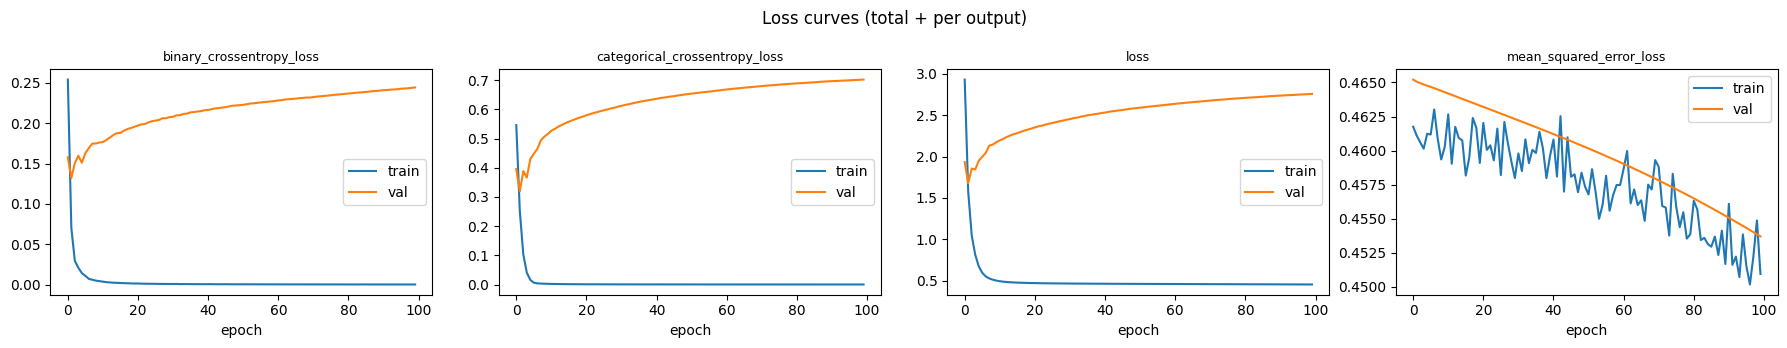

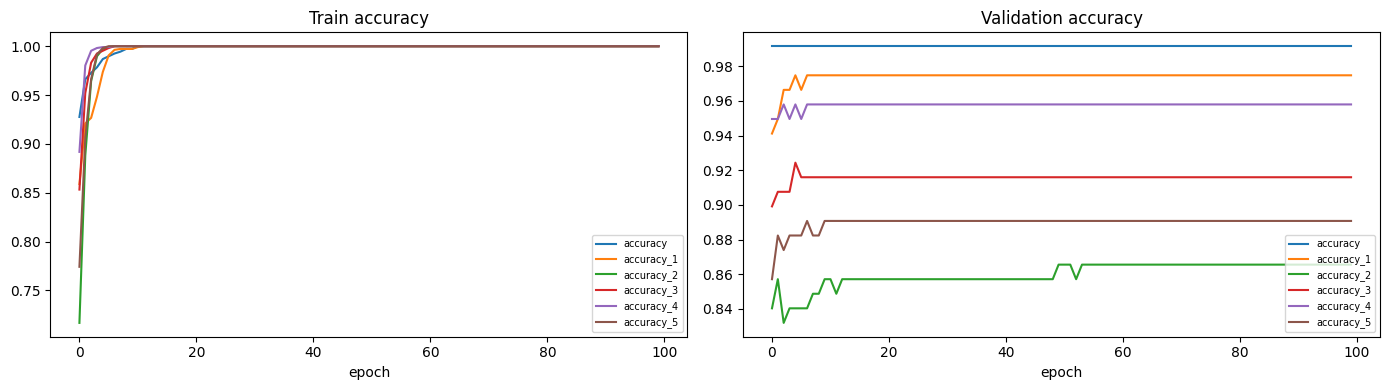

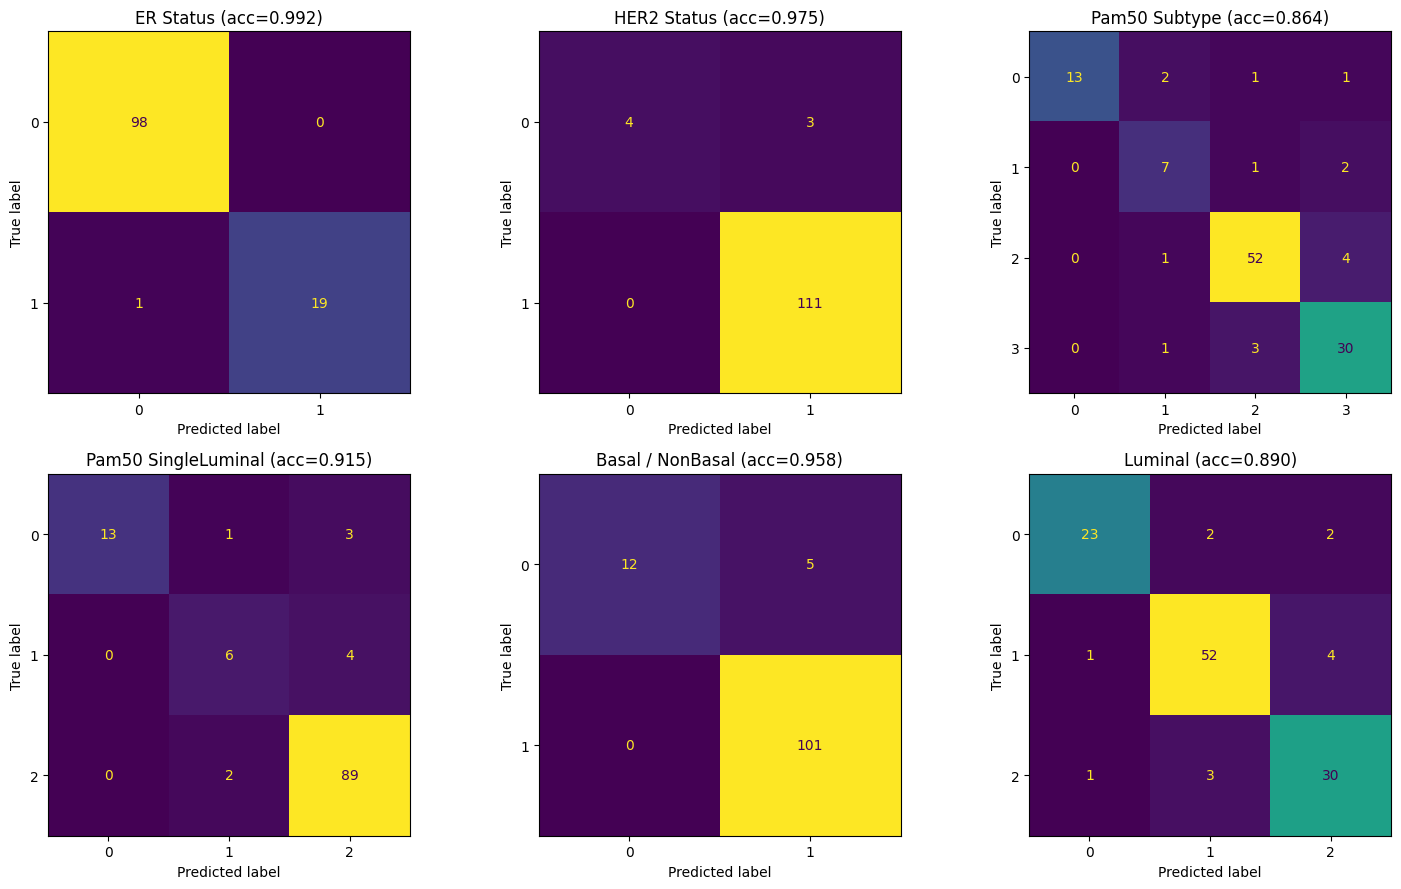

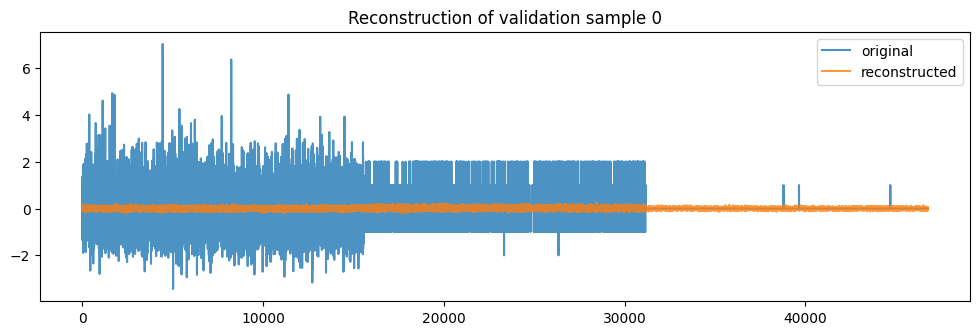

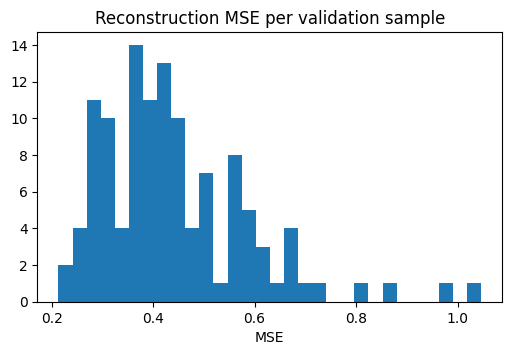

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

h = history.history

# ---------- 1) Loss curves ----------
loss_keys = [k for k in h if 'loss' in k and not k.startswith('val_')]
n = len(loss_keys)
cols = 4
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 3.5 * rows))
axes = np.array(axes).ravel()
for ax, k in zip(axes, loss_keys):
    ax.plot(h[k], label='train')
    if 'val_' + k in h:
        ax.plot(h['val_' + k], label='val')
    ax.set_title(k, fontsize=9)
    ax.set_xlabel('epoch')
    ax.legend()
for ax in axes[n:]:
    ax.axis('off')
plt.suptitle('Loss curves (total + per output)')
plt.tight_layout()
plt.show()

# ---------- 2) Accuracy curves (classifier heads only) ----------
acc_keys = [k for k in h if 'accuracy' in k and not k.startswith('val_')]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for k in acc_keys:
    axes[0].plot(h[k], label=k)
    if 'val_' + k in h:
        axes[1].plot(h['val_' + k], label=k)
axes[0].set_title('Train accuracy')
axes[1].set_title('Validation accuracy')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# ---------- 3) Confusion matrices on the validation split ----------
# validation_split=0.1 uses the LAST 10% of the data
n_val = int(len(X_array) * 0.1)
X_val = X_array[-n_val:]

preds = autoencoder.predict(X_val, verbose=0)

targets = [
    ('ER Status',            Y_data_ERStatus,                      'binary'),
    ('HER2 Status',          Y_data_HER2Status,                    'binary'),
    ('Pam50 Subtype',        Y_data_Pam50Subtype_2,                'multi'),
    ('Pam50 SingleLuminal',  Y_data_Pam50SubtypeSingleLuminal_2,   'multi'),
    ('Basal / NonBasal',     Y_data_BasalNonBasal,                 'binary'),
    ('Luminal',              Y_data_Luminal_2,                     'multi'),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_all, kind), p in zip(axes.ravel(), targets, preds[:6]):
    y_val = np.asarray(y_all)[-n_val:]
    if kind == 'binary':
        y_true = y_val.ravel().astype(int)
        y_pred = (p.ravel() > 0.5).astype(int)
    else:
        y_true = np.argmax(y_val, axis=1)
        y_pred = np.argmax(p, axis=1)
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False)
    acc = (y_true == y_pred).mean()
    ax.set_title(f'{name} (acc={acc:.3f})')
plt.tight_layout()
plt.show()

# ---------- 4) Reconstruction check ----------
decoded = preds[6]
idx = 0
plt.figure(figsize=(12, 3.5))
plt.plot(X_val[idx], label='original', alpha=0.8)
plt.plot(decoded[idx], label='reconstructed', alpha=0.8)
plt.title(f'Reconstruction of validation sample {idx}')
plt.legend()
plt.show()

# Overall reconstruction error per sample
mse = np.mean((X_val - decoded) ** 2, axis=1)
plt.figure(figsize=(6, 3.5))
plt.hist(mse, bins=30)
plt.title('Reconstruction MSE per validation sample')
plt.xlabel('MSE')
plt.show()